# L4: Clasificarea florilor cu PyTorch

Setul de date: **tf_flowers** (3670 de poze cu 5 tipuri de flori: daisy, dandelion, roses, sunflowers, tulips).

**Cum se ruleaza:**
- Intai `MOD_RAPID = True` in prima celula si **Run All**: un test de cateva minute, ca sa vedem ca merge totul.
- Apoi `MOD_RAPID = False` si **Run All**: toate cele 14 experimente, cu 5-fold cross-validation. Pe un laptop cu placa RTX 3050 a durat aprox. 20 de minute; pe procesor dureaza mai mult. Se poate lasa si peste noapte.
- Fiecare experiment terminat se salveaza, deci rularea poate fi oprita si reluata.

In [ ]:
# ======================================================================
# LAB4 - PAS 1: IMPORTURI SI SETARI
# =========================================================================
import os
import json
import copy
import time
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets.utils import download_and_extract_archive
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

MOD_RAPID = False

SEED = 42                      
MARIME_IMAGINE = 64            # imaginile sunt micsorate la 64x64 p
BATCH = 64                     
RABDARE = 5                    # early stopping
NR_FOLDURI = 2 if MOD_RAPID else 5
EPOCI_MAX = 2 if MOD_RAPID else 40

DIR_DATE = 'data'                                          
DIR_REZULTATE = 'rezultate_L4' + ('_rapid' if MOD_RAPID else '')   
DIR_MODELE = 'modele_L4' + ('_rapid' if MOD_RAPID else '')         
os.makedirs(DIR_REZULTATE, exist_ok=True)
os.makedirs(DIR_MODELE, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("PyTorch:", torch.__version__)
print("Antrenam pe:", device)
print("Procesor:", platform.processor())
if torch.cuda.is_available():
    print("Placa video:", torch.cuda.get_device_name(0))


def log(mesaj):
    print(mesaj)
    with open(os.path.join(DIR_REZULTATE, 'log.txt'), 'a', encoding='utf-8') as f:
        f.write(time.strftime('%Y-%m-%d %H:%M:%S') + '  ' + mesaj + '\n')

PyTorch: 2.6.0+cu124
Antrenam pe: cuda
Procesor: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD
Placa video: NVIDIA GeForce RTX 3050 6GB Laptop GPU


100%|██████████| 229M/229M [00:27<00:00, 8.24MB/s] 


Clase: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Forma tensorului cu imagini: (3670, 3, 64, 64)
dandelion     898
tulips        799
sunflowers    699
roses         641
daisy         633


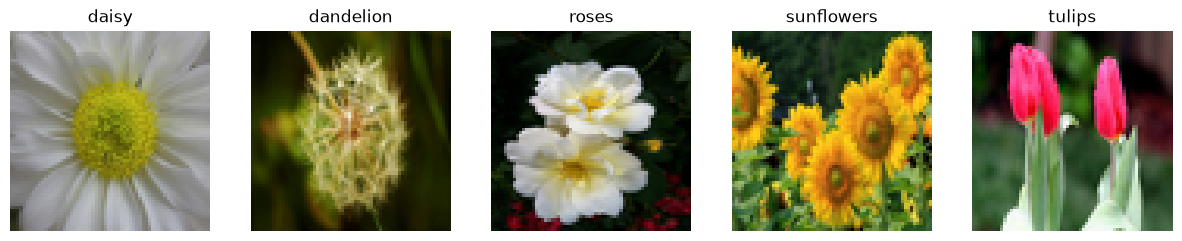

In [ ]:
# ======================================================================
# LAB4 - PAS 2: SETUL DE DATE (tf_flowers / flower_photos)
# - la prima rulare se descarca arhiva (aprox. 220 MB) in folderul data/
# - imaginile se micsoreaza la 64x64 si se salveaza intr-un fisier cache, ca rularile urmatoare sa fie rapide
# =========================================================================
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
dir_flori = os.path.join(DIR_DATE, 'flower_photos')
if not os.path.isdir(dir_flori):
    download_and_extract_archive(URL, download_root=DIR_DATE)

clase = sorted(d for d in os.listdir(dir_flori) if os.path.isdir(os.path.join(dir_flori, d)))
fisier_cache = os.path.join(DIR_DATE, f'flori_{MARIME_IMAGINE}px.pt')

if os.path.exists(fisier_cache):
    imagini, etichete, cai = torch.load(fisier_cache)
else:
    lista_imagini, lista_etichete, cai = [], [], []
    for i, clasa in enumerate(clase):
        for nume_fisier in sorted(os.listdir(os.path.join(dir_flori, clasa))):
            if not nume_fisier.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            cale = os.path.join(dir_flori, clasa, nume_fisier)
            img = Image.open(cale).convert('RGB').resize((MARIME_IMAGINE, MARIME_IMAGINE))
            lista_imagini.append(torch.from_numpy(np.array(img)).permute(2, 0, 1))
            lista_etichete.append(i)
            cai.append(cale)
    imagini = torch.stack(lista_imagini)        # valori intregi 0-255, forma (N, 3, 64, 64)
    etichete = torch.tensor(lista_etichete)
    torch.save((imagini, etichete, cai), fisier_cache)

if MOD_RAPID:
    idx = torch.cat([torch.nonzero(etichete == c).flatten()[:40] for c in range(len(clase))])
    imagini, etichete, cai = imagini[idx], etichete[idx], [cai[i] for i in idx.tolist()]

print("Clase:", clase)
print("Forma tensorului cu imagini:", tuple(imagini.shape))
print(pd.Series(etichete.numpy()).map(dict(enumerate(clase))).value_counts().to_string())

fig, axe = plt.subplots(1, len(clase), figsize=(3 * len(clase), 3))
for c, ax in enumerate(axe):
    i = torch.nonzero(etichete == c).flatten()[0].item()
    ax.imshow(imagini[i].permute(1, 2, 0).numpy())
    ax.set_title(clase[c])
    ax.axis('off')
plt.show()

### Interpretare: setul de date

- Setul are 3670 de poze: daisy 633, dandelion 898, roses 641, sunflowers 699, tulips 799. Clasele nu sunt perfect echilibrate
- Folosim macro-F1 pentru ca face media scorurilor pe cele 5 flori, fiecare contand la fel, chiar daca una are mai putine poze.
- La 64x64 pixeli se pierd detaliile. Raman culoarea, forma generala si fundalul, lucru care se vede si la greseli: florile cu culori asemanatoare se confunda.

In [ ]:
# ======================================================================
# LAB4 - PAS 3: CUM AJUNG IMAGINILE IN RETEA (Dataset, normalizare, augmentare)
# - normalizare -1 si 1
# - augmentare: oglindire stanga-dreapta si rotire usoara
# =========================================================================
class SetFlori(Dataset):
    def __init__(self, imagini, etichete, augmentare=False):
        self.imagini = imagini
        self.etichete = etichete
        if augmentare:
            self.augmentare = transforms.Compose([transforms.RandomHorizontalFlip(),
                                                  transforms.RandomRotation(15)])
        else:
            self.augmentare = None

    def __len__(self):
        return len(self.etichete)

    def __getitem__(self, i):
        x = self.imagini[i].float() / 255.0          # 0-255 -> 0-1
        if self.augmentare is not None:
            x = self.augmentare(x)
        x = (x - 0.5) / 0.5                          # 0-1 -> -1..1
        return x, self.etichete[i]

In [ ]:
# ======================================================================
# LAB4 - PAS 4: RETEAUA NEURONALA, CONSTRUITA DIN SETARILE EXPERIMENTULUI
# - straturi convolutionale (0-6), fiecare cu: convolutie 3x3 -> [batch norm] -> activare -> [max pooling]
# - [optional] un strat recurent (GRU) care citeste imaginea rand cu rand
# - straturi ascunse complet conectate (1-3), fiecare cu: liniar -> [batch norm] -> activare -> dropout
# - stratul de iesire: cate un neuron pentru fiecare clasa de flori
# =========================================================================
ACTIVARI = {'relu': nn.ReLU, 'leaky_relu': nn.LeakyReLU, 'tanh': nn.Tanh}


class ReteaFlori(nn.Module):
    def __init__(self, cfg, nr_clase):
        super().__init__()
        activare = ACTIVARI[cfg['activare']]

        # partea convolutionala
        straturi = []
        canale, marime = 3, MARIME_IMAGINE
        for filtre in cfg['conv']:
            straturi.append(nn.Conv2d(canale, filtre, kernel_size=3, padding=1))
            if cfg['batch_norm']:
                straturi.append(nn.BatchNorm2d(filtre))
            straturi.append(activare())
            if cfg['pooling']:
                straturi.append(nn.MaxPool2d(2))     # pooling
                marime //= 2
            canale = filtre
        self.conv = nn.Sequential(*straturi)

        # partea recurenta
        self.recurent = cfg['recurent']
        if self.recurent:
            self.gru = nn.GRU(input_size=canale * marime, hidden_size=128, batch_first=True)
            intrari = 128
        else:
            intrari = canale * marime * marime

        # partea complet conectata
        dense = []
        for neuroni in cfg['hidden']:
            dense.append(nn.Linear(intrari, neuroni))
            if cfg['batch_norm']:
                dense.append(nn.BatchNorm1d(neuroni))
            dense.append(activare())
            dense.append(nn.Dropout(cfg['dropout']))
            intrari = neuroni
        dense.append(nn.Linear(intrari, nr_clase))
        self.dense = nn.Sequential(*dense)

    def forward(self, x):
        x = self.conv(x)
        if self.recurent:
            # (batch, canale, inaltime, latime) -> (batch, inaltime, canale * latime)
            x = x.permute(0, 2, 1, 3).flatten(2)
            _, ultima_stare = self.gru(x)
            x = ultima_stare[-1]
        else:
            x = x.flatten(1)                         
        return self.dense(x)


def numara_parametri(model):
    return sum(p.numel() for p in model.parameters())

In [ ]:
# ======================================================================
# LAB4 - PAS 5: EXPERIMENTELE (in stilul grid search)
# - pornim de la o retea de baza si schimbam cate un lucru odata
# =========================================================================
BAZA = dict(conv=[16, 32, 64, 128], pooling=True, hidden=[128], activare='relu', lr=1e-3,
            l1=0.0, l2=0.0, batch_norm=False, dropout=0.0, augmentare=False, recurent=False)


def experiment(nume, **schimbari):
    cfg = dict(BAZA)
    cfg.update(schimbari)
    cfg['nume'] = nume
    return cfg


EXPERIMENTE = [
    experiment('01_fara_conv', conv=[], hidden=[256]),
    experiment('02_conv2_pool', conv=[16, 32]),
    experiment('03_conv2_fara_pool', conv=[16, 32], pooling=False),
    experiment('04_conv4_baza'),
    experiment('05_conv6', conv=[16, 32, 64, 128, 128, 128]),
    experiment('06_3_ascunse', hidden=[256, 128, 64]),
    experiment('07_tanh', activare='tanh'),
    experiment('08_leaky_lr_mic', activare='leaky_relu', lr=1e-4),
    experiment('09_lr_mare', lr=1e-2),
    experiment('10_l2', l2=1e-3),
    experiment('11_l1', l1=1e-5),
    experiment('12_bn_dropout05', batch_norm=True, dropout=0.5),
    experiment('13_dropout025_augm', dropout=0.25, augmentare=True),
    experiment('14_conv_gru', conv=[16, 32], recurent=True),
]

tabel = pd.DataFrame(EXPERIMENTE).set_index('nume')
tabel['parametri'] = [numara_parametri(ReteaFlori(cfg, len(clase))) for cfg in EXPERIMENTE]
print(tabel.to_string())

                                           conv  pooling          hidden    activare      lr       l1     l2  batch_norm  dropout  augmentare  recurent  parametri
nume                                                                                                                                                              
01_fara_conv                                 []     True           [256]        relu  0.0010  0.00000  0.000       False     0.00       False     False    3147269
02_conv2_pool                          [16, 32]     True           [128]        relu  0.0010  0.00000  0.000       False     0.00       False     False    1054437
03_conv2_fara_pool                     [16, 32]    False           [128]        relu  0.0010  0.00000  0.000       False     0.00       False     False   16783077
04_conv4_baza                 [16, 32, 64, 128]     True           [128]        relu  0.0010  0.00000  0.000       False     0.00       False     False     360357
05_conv6            [1

### Interpretare: experimentele

- **Cei mai multi parametri** are experimentul 03 (fara pooling): 16,8 milioane. Fara pooling imaginea ramane 64x64, deci dupa ultima convolutie vectorul are 32 x 64 x 64 = 131.072 de valori, iar primul strat complet conectat (131.072 x 128) are singur 16,8 milioane de ponderi.
- **Pooling-ul reduce mult parametrii:** injumatateste inaltimea si latimea la fiecare strat. Cu pooling, aceeasi retea are 1 milion de parametri.
- **Cei mai putini parametri** are experimentul 14 (convolutii + GRU): 268 mii.
- **Cu 6 straturi convolutionale (05) sunt 409.765 de parametri, putin mai multi decat cu 4 (360.357)**. Straturile convolutionale adauga parametri, dar mai mult pooling face vectorul final mai mic (128 in loc de 2048), deci stratul complet conectat se micsoreaza mult.
- Concluzie: in aceste retele, cei mai multi parametri stau in primul strat complet conectat, iar dimensiunea lui depinde de cat de mult a micsorat pooling-ul imaginea.

In [ ]:
# ======================================================================
# LAB4 - PAS 6: ANTRENAREA UNUI MODEL (cu early stopping, L1, L2)
# - L1 se adauga manual la loss: suma valorilor absolute ale tuturor ponderilor
# - dupa fiecare epoca: loss si macro-F1 pe antrenare si pe validare
# =========================================================================
def evalueaza(model, dl, loss_fn, device):
    model.eval()
    total, predictii, adevarate = 0.0, [], []
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            iesire = model(x)
            total += loss_fn(iesire, y).item() * len(y)
            predictii += iesire.argmax(1).tolist()
            adevarate += y.tolist()
    return total / len(adevarate), predictii, adevarate


def antreneaza(cfg, idx_antr, idx_val, device, epoci_max=EPOCI_MAX):
    torch.manual_seed(SEED)
    model = ReteaFlori(cfg, len(clase)).to(device)
    optimizator = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['l2'])
    loss_fn = nn.CrossEntropyLoss()
    # drop_last
    dl_antr = DataLoader(SetFlori(imagini[idx_antr], etichete[idx_antr], cfg['augmentare']),
                         batch_size=BATCH, shuffle=True, drop_last=True)
    dl_val = DataLoader(SetFlori(imagini[idx_val], etichete[idx_val]), batch_size=BATCH)

    istoric = {'loss_antr': [], 'loss_val': [], 'f1_antr': [], 'f1_val': []}
    cel_mai_bun = {'loss': float('inf'), 'stare': None, 'pred': None, 'epoca': 0}
    epoci_fara_progres = 0
    start = time.time()

    for epoca in range(epoci_max):
        model.train()
        total, predictii, adevarate = 0.0, [], []
        for x, y in dl_antr:
            x, y = x.to(device), y.to(device)
            iesire = model(x)
            loss = loss_fn(iesire, y)
            if cfg['l1'] > 0:
                loss = loss + cfg['l1'] * sum(p.abs().sum() for p in model.parameters())
            optimizator.zero_grad()
            loss.backward()
            optimizator.step()
            total += loss.item() * len(y)
            predictii += iesire.argmax(1).tolist()
            adevarate += y.tolist()

        loss_val, pred_val, adev_val = evalueaza(model, dl_val, loss_fn, device)
        istoric['loss_antr'].append(total / len(adevarate))
        istoric['loss_val'].append(loss_val)
        istoric['f1_antr'].append(f1_score(adevarate, predictii, average='macro'))
        istoric['f1_val'].append(f1_score(adev_val, pred_val, average='macro'))

        if loss_val < cel_mai_bun['loss']:
            cel_mai_bun = {'loss': loss_val, 'stare': copy.deepcopy(model.state_dict()),
                           'pred': pred_val, 'epoca': epoca + 1}
            epoci_fara_progres = 0
        else:
            epoci_fara_progres += 1
            if epoci_fara_progres >= RABDARE:
                break                                # early stopping

    durata = time.time() - start
    model.load_state_dict(cel_mai_bun['stare'])
    return model, istoric, cel_mai_bun, durata

In [ ]:
# ======================================================================
# LAB4 - PAS 7: RULAREA TUTUROR EXPERIMENTELOR CU 5-FOLD CROSS-VALIDATION
# - acelasi random seed
# - rezultatele se adauga in rezultate.csv
# =========================================================================
skf = StratifiedKFold(n_splits=NR_FOLDURI, shuffle=True, random_state=SEED)
folduri = list(skf.split(np.zeros(len(etichete)), etichete.numpy()))
fisier_rezultate = os.path.join(DIR_REZULTATE, 'rezultate.csv')

for cfg in EXPERIMENTE:
    nume = cfg['nume']
    dir_exp = os.path.join(DIR_REZULTATE, nume)
    if os.path.exists(os.path.join(dir_exp, 'pred_oof.npy')):
        log(f"{nume}: deja rulat, il sarim")
        continue
    os.makedirs(dir_exp, exist_ok=True)
    log(f"=== {nume} ===")

    #fiecare imagine e prezisa de modelul care Nu a vazut-o la antrenare
    pred_oof = np.full(len(etichete), -1)
    istorice, f1_folduri, durate, epoci = [], [], [], []
    for k, (idx_antr, idx_val) in enumerate(folduri):
        model, istoric, cel_mai_bun, durata = antreneaza(cfg, idx_antr, idx_val, device)
        pred_oof[idx_val] = cel_mai_bun['pred']
        f1_folduri.append(f1_score(etichete[idx_val].numpy(), cel_mai_bun['pred'], average='macro'))
        istorice.append(istoric)
        durate.append(durata)
        epoci.append(cel_mai_bun['epoca'])
        if k == 0:
            cale_model = os.path.join(DIR_MODELE, f'{nume}.pt')
            torch.save(model.state_dict(), cale_model)
        log(f"  fold {k + 1}: macro-F1 {f1_folduri[-1]:.3f} | cea mai buna epoca {cel_mai_bun['epoca']} "
            f"| {len(istoric['loss_val'])} epoci rulate | {durata:.0f} s")

    np.save(os.path.join(dir_exp, 'pred_oof.npy'), pred_oof)
    with open(os.path.join(dir_exp, 'istoric.json'), 'w') as f:
        json.dump(istorice, f)

    rand = {'experiment': nume,
            'macro_f1_medie': round(float(np.mean(f1_folduri)), 4),
            'macro_f1_std': round(float(np.std(f1_folduri)), 4),
            'parametri': numara_parametri(model),
            'timp_antrenare_s': round(sum(durate), 1),
            'epoca_optima_medie': round(float(np.mean(epoci)), 1),
            'marime_model_MB': round(os.path.getsize(cale_model) / 1e6, 2),
            'device': str(device)}
    rezultate = pd.read_csv(fisier_rezultate) if os.path.exists(fisier_rezultate) else pd.DataFrame()
    rezultate = pd.concat([rezultate, pd.DataFrame([rand])], ignore_index=True)
    rezultate.to_csv(fisier_rezultate, index=False)
    log(f"  {nume}: macro-F1 {rand['macro_f1_medie']:.3f} +/- {rand['macro_f1_std']:.3f}")

=== 01_fara_conv ===
  fold 1: macro-F1 0.499 | cea mai buna epoca 4 | 9 epoci rulate | 6 s
  fold 2: macro-F1 0.427 | cea mai buna epoca 1 | 6 epoci rulate | 3 s
  fold 3: macro-F1 0.472 | cea mai buna epoca 4 | 9 epoci rulate | 5 s
  fold 4: macro-F1 0.468 | cea mai buna epoca 3 | 8 epoci rulate | 4 s
  fold 5: macro-F1 0.483 | cea mai buna epoca 3 | 8 epoci rulate | 4 s
  01_fara_conv: macro-F1 0.470 +/- 0.024
=== 02_conv2_pool ===
  fold 1: macro-F1 0.643 | cea mai buna epoca 5 | 10 epoci rulate | 7 s
  fold 2: macro-F1 0.623 | cea mai buna epoca 4 | 9 epoci rulate | 5 s
  fold 3: macro-F1 0.633 | cea mai buna epoca 6 | 11 epoci rulate | 6 s
  fold 4: macro-F1 0.626 | cea mai buna epoca 6 | 11 epoci rulate | 6 s
  fold 5: macro-F1 0.681 | cea mai buna epoca 8 | 13 epoci rulate | 8 s
  02_conv2_pool: macro-F1 0.641 +/- 0.021
=== 03_conv2_fara_pool ===
  fold 1: macro-F1 0.593 | cea mai buna epoca 4 | 9 epoci rulate | 13 s
  fold 2: macro-F1 0.572 | cea mai buna epoca 3 | 8 epoci rul

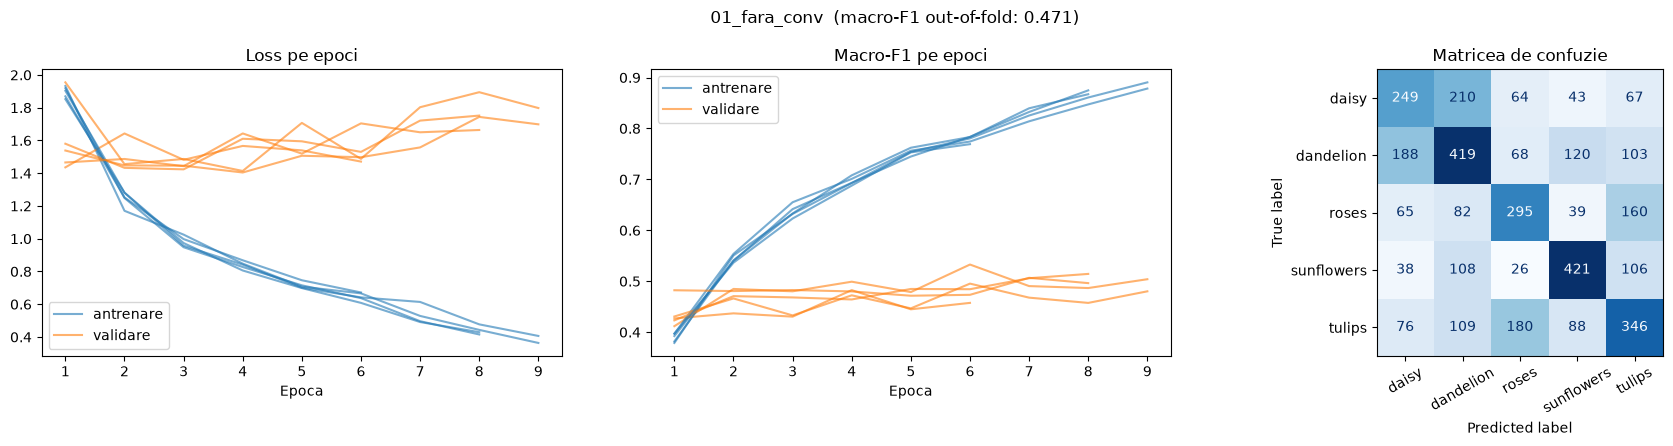

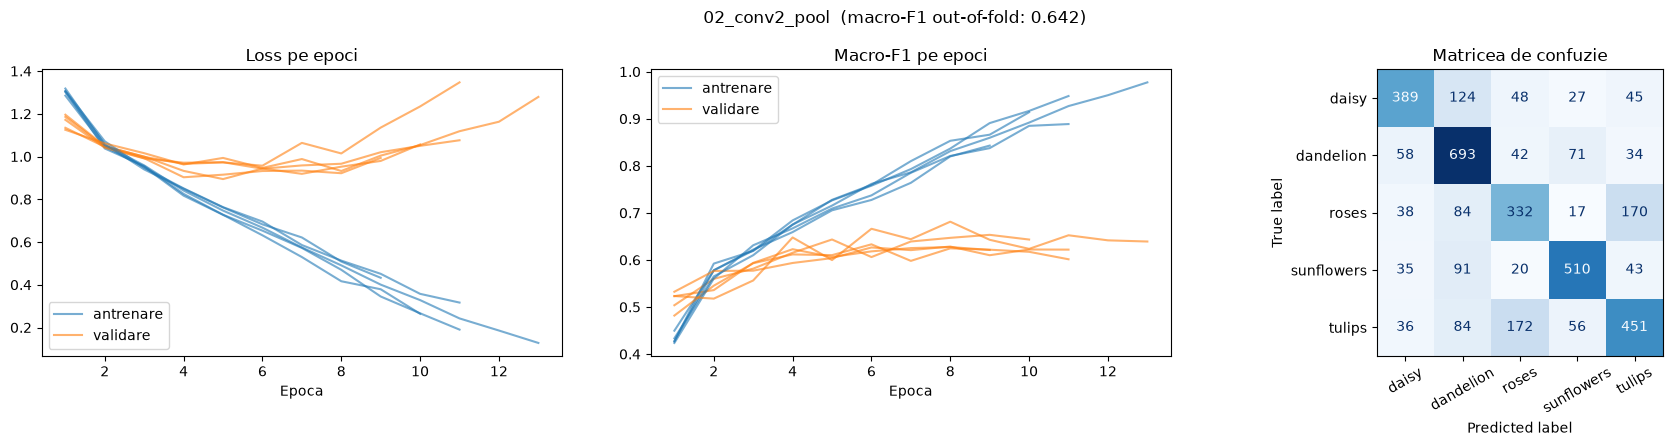

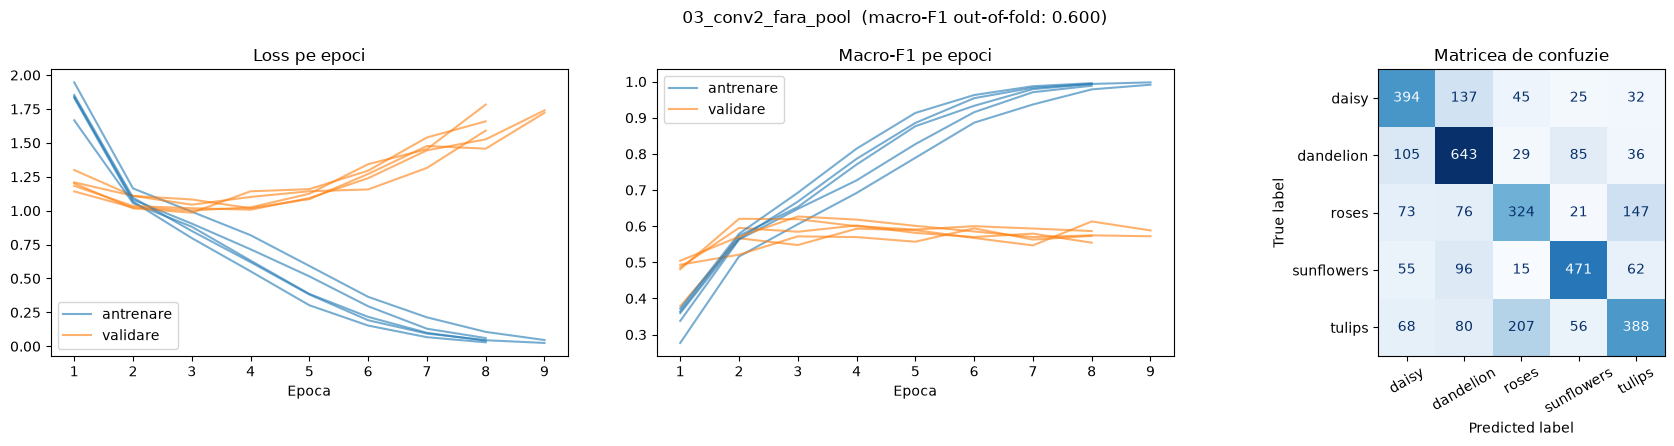

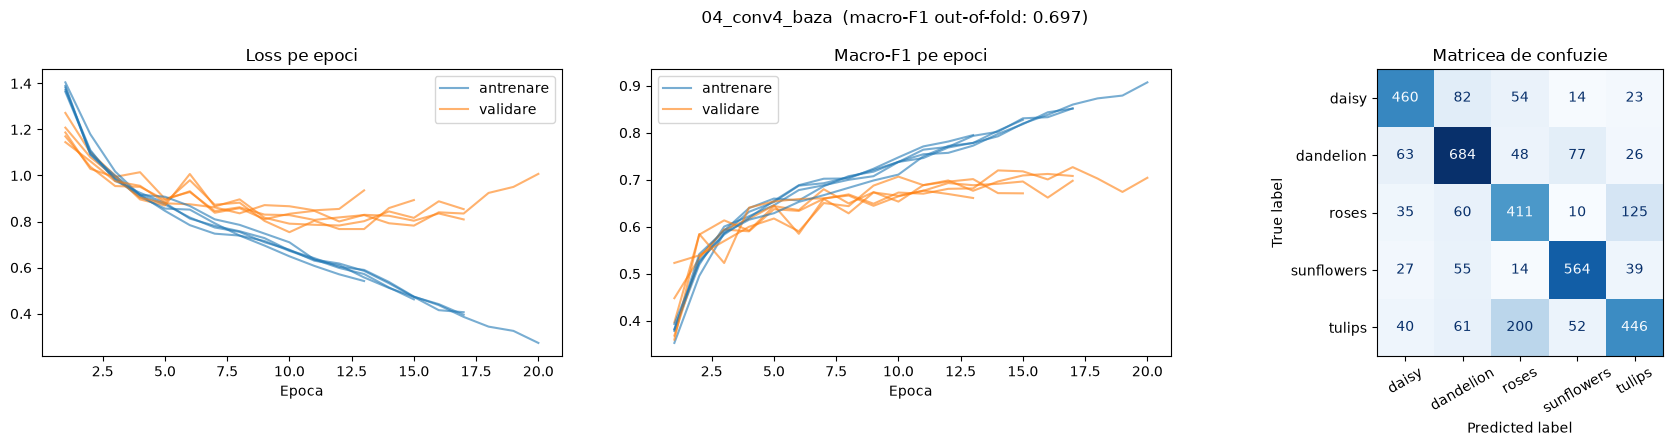

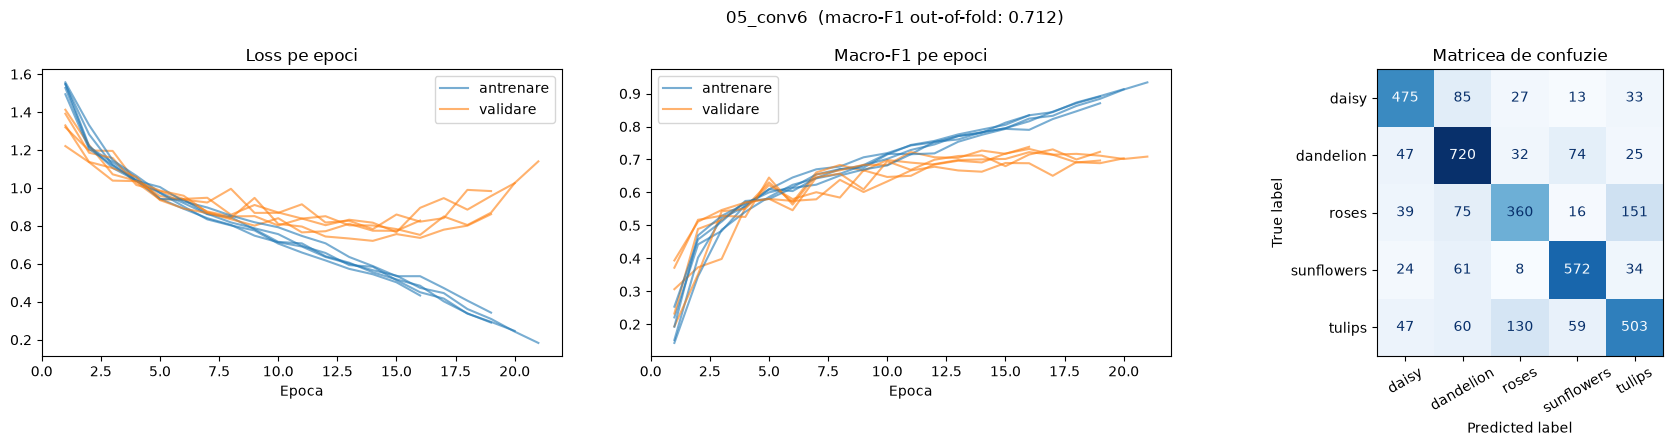

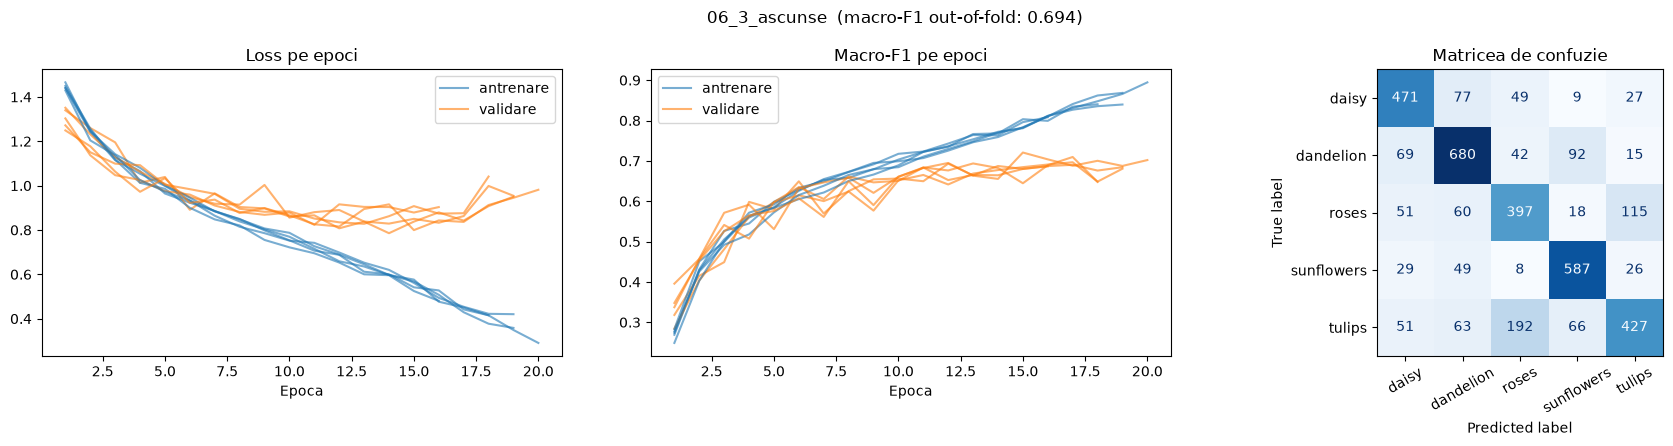

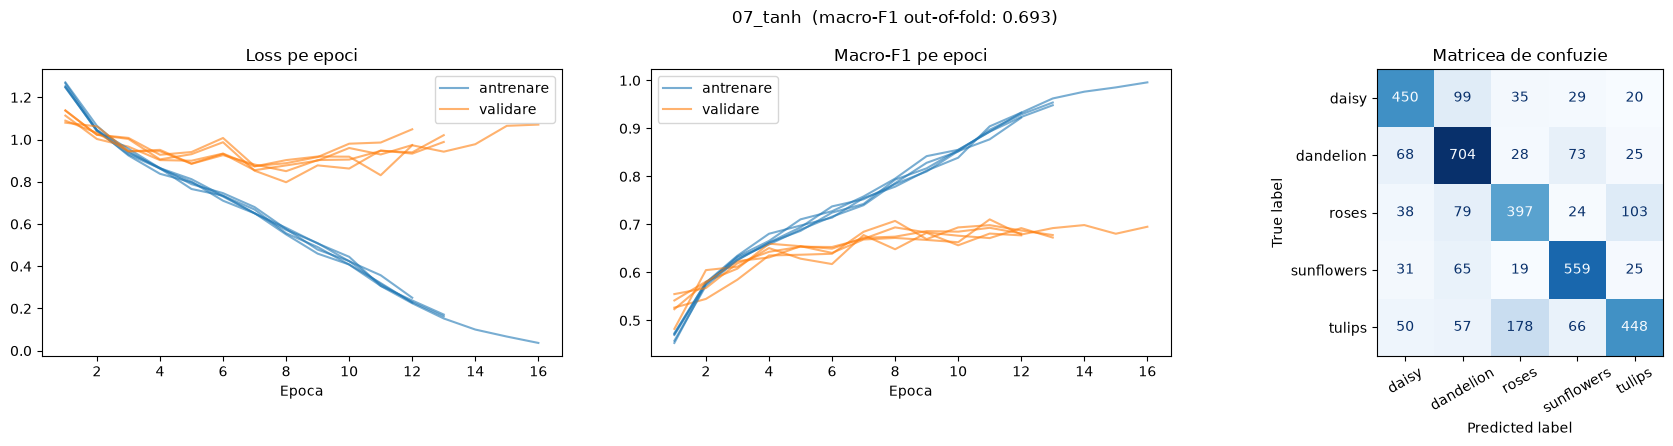

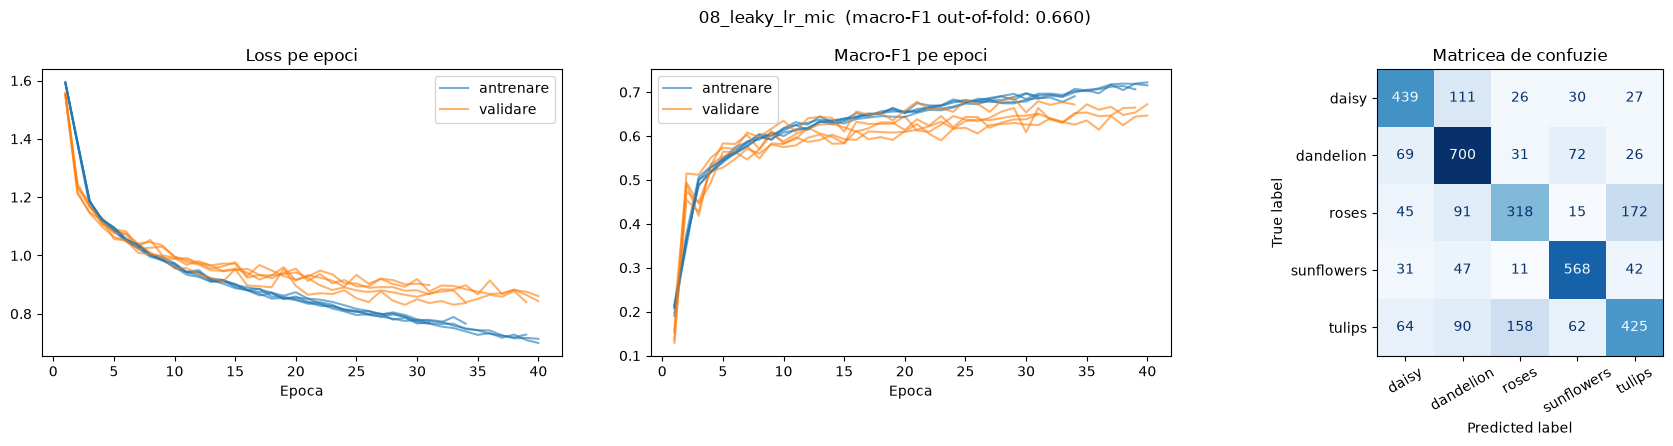

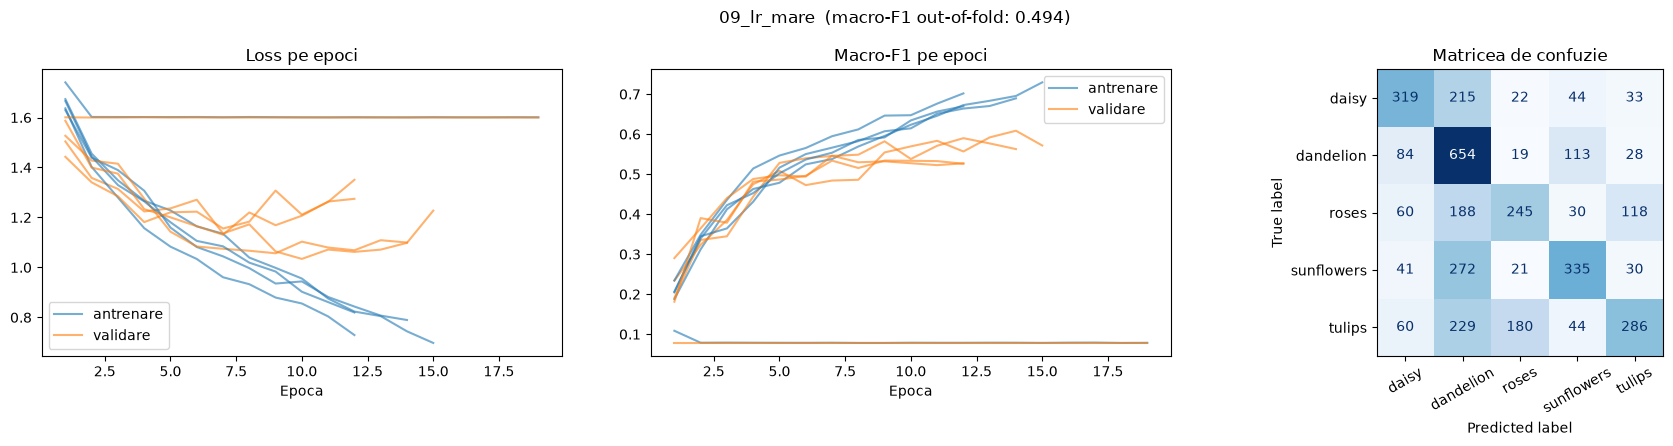

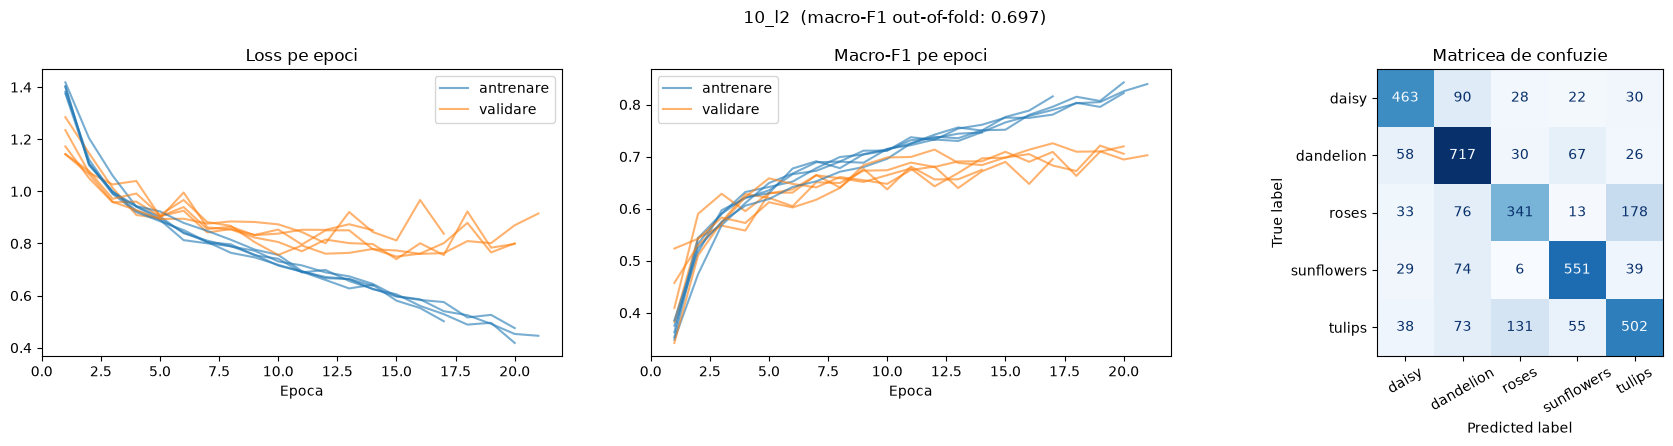

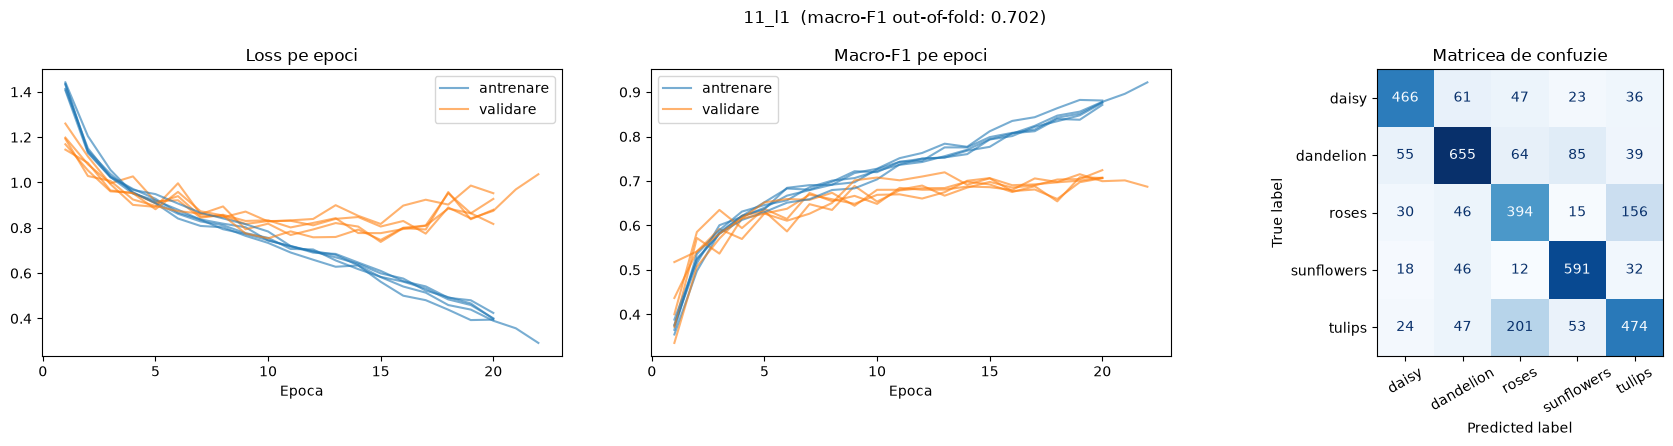

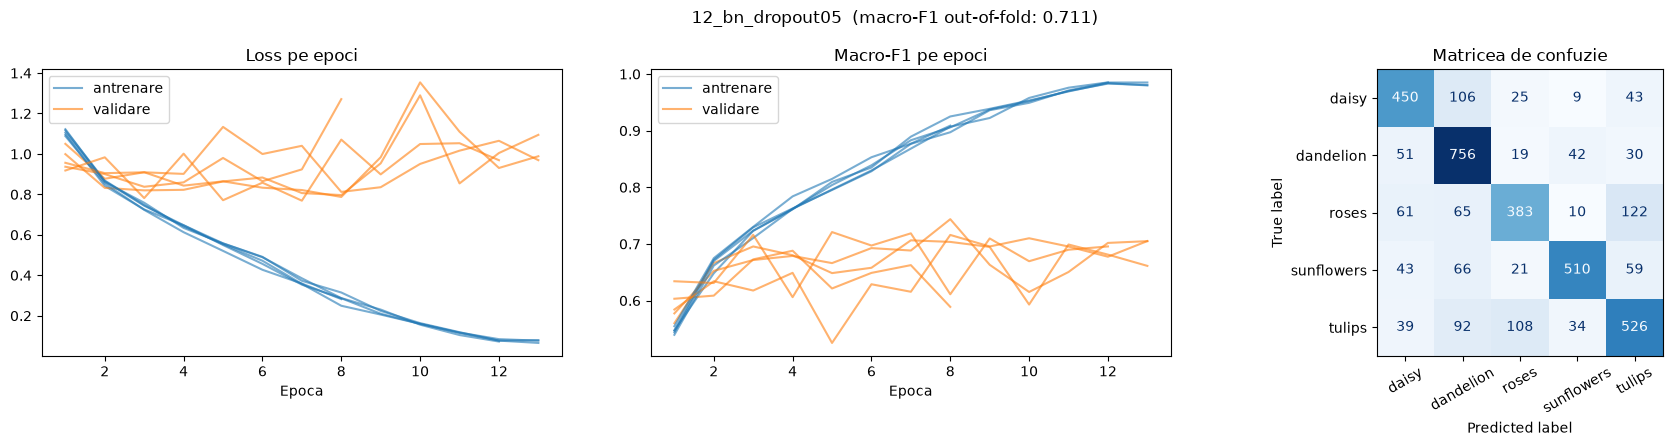

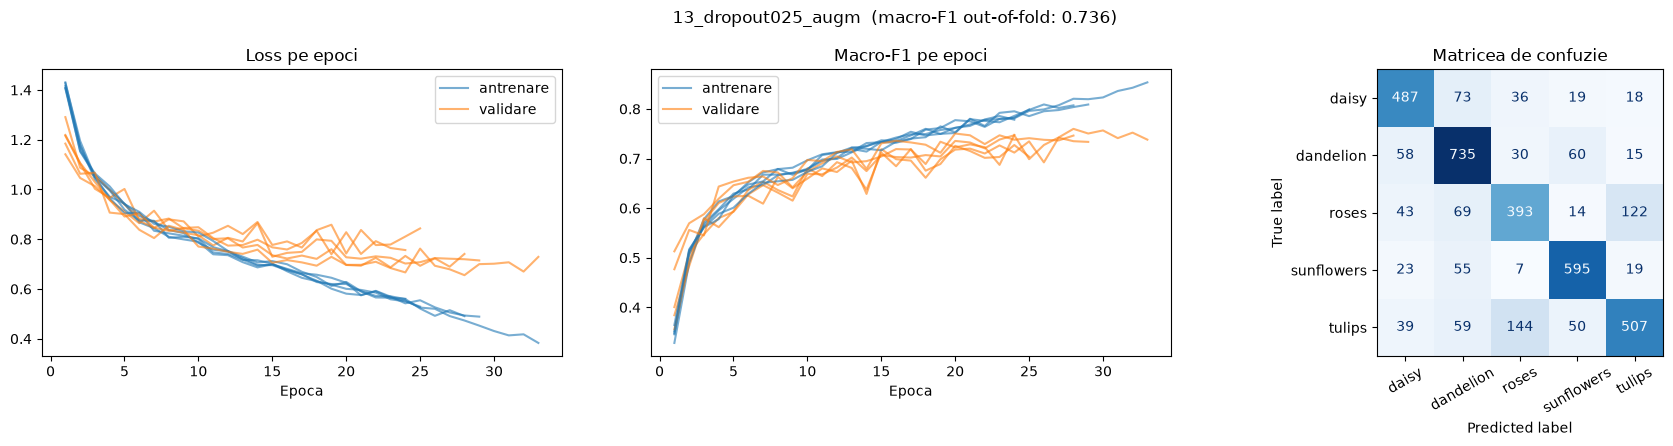

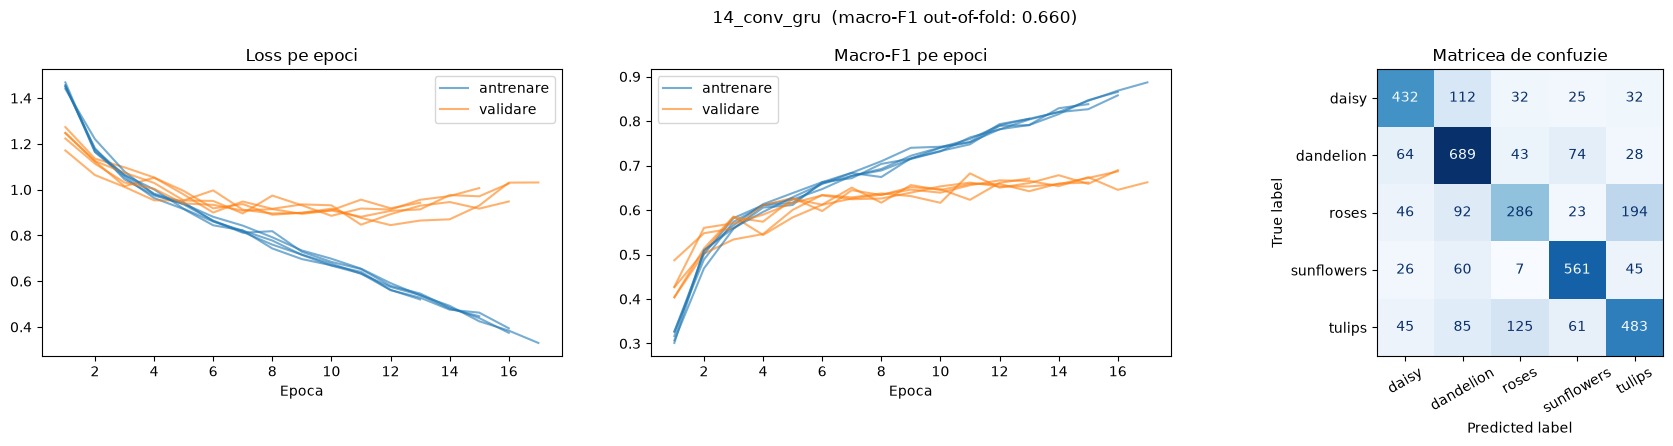

In [8]:
# ======================================================================
# LAB4 - PAS 8: GRAFICE PENTRU FIECARE EXPERIMENT
# - loss pe antrenare / validare pe epoci (cate o linie pentru fiecare fold)
# - macro-F1 pe antrenare / validare pe epoci
# - matricea de confuzie, din predictiile out-of-fold (toate imaginile)
# =========================================================================
for cfg in EXPERIMENTE:
    nume = cfg['nume']
    dir_exp = os.path.join(DIR_REZULTATE, nume)
    if not os.path.exists(os.path.join(dir_exp, 'pred_oof.npy')):
        continue
    with open(os.path.join(dir_exp, 'istoric.json')) as f:
        istorice = json.load(f)
    pred_oof = np.load(os.path.join(dir_exp, 'pred_oof.npy'))

    fig, axe = plt.subplots(1, 3, figsize=(18, 4.5))
    for k, ist in enumerate(istorice):
        ep = range(1, len(ist['loss_antr']) + 1)
        axe[0].plot(ep, ist['loss_antr'], color='tab:blue', alpha=0.6, label='antrenare' if k == 0 else None)
        axe[0].plot(ep, ist['loss_val'], color='tab:orange', alpha=0.6, label='validare' if k == 0 else None)
        axe[1].plot(ep, ist['f1_antr'], color='tab:blue', alpha=0.6, label='antrenare' if k == 0 else None)
        axe[1].plot(ep, ist['f1_val'], color='tab:orange', alpha=0.6, label='validare' if k == 0 else None)
    axe[0].set_title('Loss pe epoci')
    axe[0].set_xlabel('Epoca')
    axe[0].legend()
    axe[1].set_title('Macro-F1 pe epoci')
    axe[1].set_xlabel('Epoca')
    axe[1].legend()
    ConfusionMatrixDisplay(confusion_matrix(etichete.numpy(), pred_oof),
                           display_labels=clase).plot(ax=axe[2], cmap='Blues', colorbar=False)
    axe[2].set_title('Matricea de confuzie')
    plt.setp(axe[2].get_xticklabels(), rotation=30)
    fig.suptitle(f"{nume}  (macro-F1 out-of-fold: {f1_score(etichete.numpy(), pred_oof, average='macro'):.3f})")
    plt.tight_layout()
    plt.savefig(os.path.join(dir_exp, 'grafice.png'), dpi=80)
    plt.show()

### Interpretare: graficele pe epoci si matricile de confuzie

**Overfitting**
- La aproape toate experimentele, loss-ul de antrenare scade continuu, iar cel de validare se opreste sau chiar creste dupa cateva epoci. Macro-F1 pe antrenare urca spre 0.9, pe cand pe validare ramane in jur de 0.7 (de exemplu experimentul 04).
- Cel mai tare se vede la experimentul 01 (fara convolutii): macro-F1 pe antrenare ajunge la 0.9, pe validare ramane in jur de 0.5, iar loss-ul de validare creste din epoca 3. Early stopping opreste antrenarea dupa doar 3-4 epoci.

**Regularizarea ajuta**
- La experimentul 13 (dropout 0.25 + augmentare), curbele de antrenare si de validare raman apropiate mult mai mult (pana pe la epoca 15-20), antrenarea continua pana la aproximativ 23 de epoci, iar macro-F1 pe validare ajunge la 0.73-0.75.

**Rata de invatare prea mare (experimentul 09)**
- Una dintre cele 5 retele nu a invatat deloc: loss-ul ei ramane pe 1.6 (aproximativ ln 5, adica ghicit la intamplare intre 5 clase) si macro-F1 pe 0.08. Celelalte 4 invata, dar curbele de validare sar in sus si in jos. De aceea abaterea standard a acestui experiment e foarte mare (0.19).

**Matricile de confuzie**
- Cea mai frecventa confuzie e intre **trandafiri si lalele**: la experimentul 04, 200 de lalele sunt prezise ca trandafiri si 125 de trandafiri sunt prezisi ca lalele. Urmeaza daisy prezisa ca dandelion (82).
- Florile-soarelui si papadiile (dandelion) sunt recunoscute cel mai bine. Trandafirii si lalelele cel mai prost.
- Explicatie: trandafirii si lalele au forme si culori asemanatoare (rosu, roz), iar la 64x64 pixeli diferentele de forma se vad greu. Florile-soarelui si papadiile au o culoare galbena foarte specifica.

        experiment  macro_f1_medie  macro_f1_std  parametri  timp_antrenare_s  epoca_optima_medie  marime_model_MB device
13_dropout025_augm          0.7357        0.0166     360357             343.4                22.8             1.45   cuda
          05_conv6          0.7113        0.0152     409765              60.5                14.0             1.64   cuda
   12_bn_dropout05          0.7109        0.0231     361093              41.2                 6.8             1.46   cuda
             11_l1          0.7017        0.0057     360357              63.4                15.4             1.45   cuda
     04_conv4_baza          0.6964        0.0172     360357              52.4                11.4             1.45   cuda
             10_l2          0.6955        0.0148     360357              56.9                13.4             1.45   cuda
      06_3_ascunse          0.6925        0.0151     663461              54.0                13.4             2.66   cuda
           07_tanh      

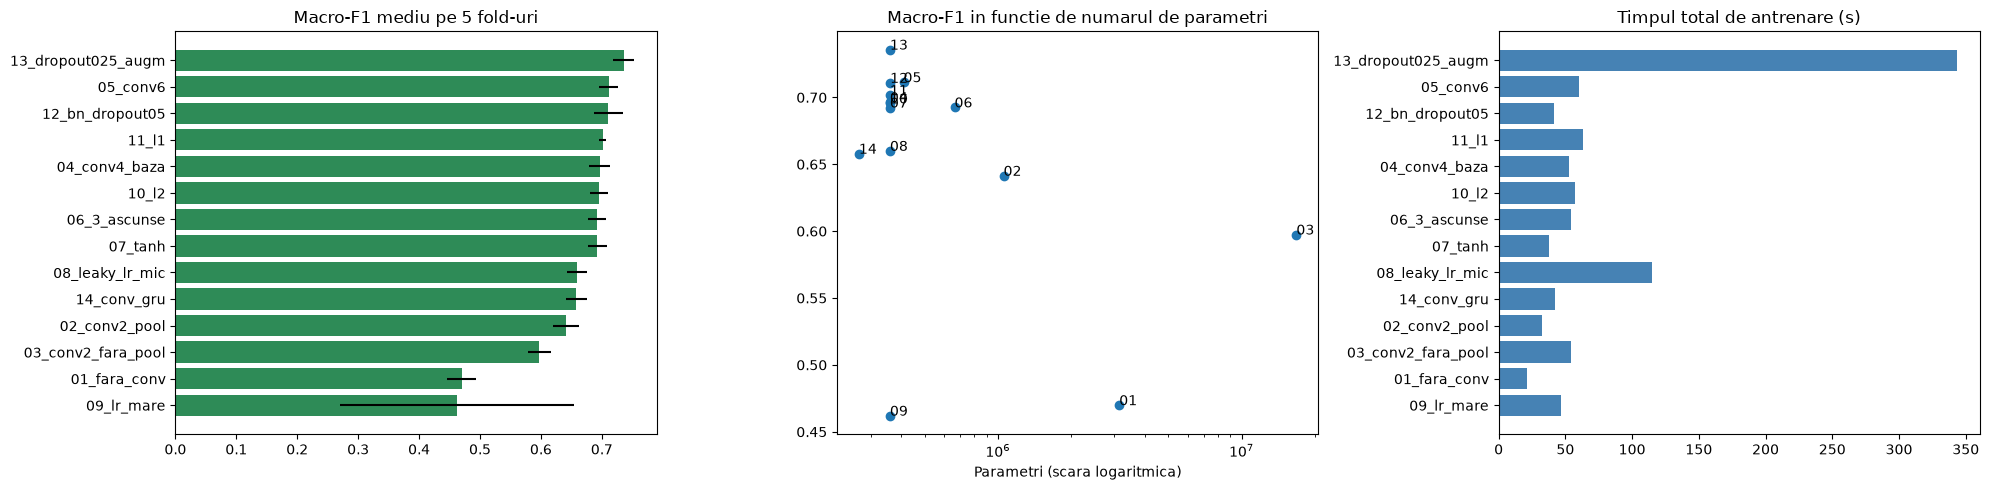


Marimea modelelor salvate pe disc:
  01_fara_conv.pt                   12.59 MB
  02_conv2_pool.pt                   4.22 MB
  03_conv2_fara_pool.pt             67.14 MB
  04_conv4_baza.pt                   1.45 MB
  05_conv6.pt                        1.64 MB
  06_3_ascunse.pt                    2.66 MB
  07_tanh.pt                         1.45 MB
  08_leaky_lr_mic.pt                 1.45 MB
  09_lr_mare.pt                      1.45 MB
  10_l2.pt                           1.45 MB
  11_l1.pt                           1.45 MB
  12_bn_dropout05.pt                 1.46 MB
  13_dropout025_augm.pt              1.45 MB
  14_conv_gru.pt                     1.08 MB


In [9]:
# ======================================================================
# LAB4 - PAS 9: COMPARATIA EXPERIMENTELOR
# - calitatea (macro-F1), numarul de parametri, timpul de antrenare, marimea modelului pe disc
# =========================================================================
rezultate = pd.read_csv(fisier_rezultate).sort_values('macro_f1_medie', ascending=False)
print(rezultate.to_string(index=False))

fig, axe = plt.subplots(1, 3, figsize=(20, 5))
axe[0].barh(rezultate['experiment'], rezultate['macro_f1_medie'], xerr=rezultate['macro_f1_std'], color='seagreen')
axe[0].set_title('Macro-F1 mediu pe 5 fold-uri')
axe[0].invert_yaxis()
axe[1].scatter(rezultate['parametri'], rezultate['macro_f1_medie'])
for _, r in rezultate.iterrows():
    axe[1].annotate(r['experiment'][:2], (r['parametri'], r['macro_f1_medie']))
axe[1].set_xscale('log')
axe[1].set_title('Macro-F1 in functie de numarul de parametri')
axe[1].set_xlabel('Parametri (scara logaritmica)')
axe[2].barh(rezultate['experiment'], rezultate['timp_antrenare_s'], color='steelblue')
axe[2].set_title('Timpul total de antrenare (s)')
axe[2].invert_yaxis()
plt.tight_layout()
plt.show()

print("\nMarimea modelelor salvate pe disc:")
for nume_fisier in sorted(os.listdir(DIR_MODELE)):
    print(f"  {nume_fisier:30s} {os.path.getsize(os.path.join(DIR_MODELE, nume_fisier)) / 1e6:8.2f} MB")

### Interpretare: comparatia experimentelor

| Experiment | Macro-F1 | Parametri | Timp total | Pe disc |
|---|---|---|---|---|
| 13_dropout025_augm | 0.736 | 360.357 | 343 s | 1.45 MB |
| 05_conv6 | 0.711 | 409.765 | 60 s | 1.64 MB |
| 12_bn_dropout05 | 0.711 | 361.093 | 41 s | 1.46 MB |
| 11_l1 | 0.702 | 360.357 | 63 s | 1.45 MB |
| 04_conv4_baza | 0.696 | 360.357 | 52 s | 1.45 MB |
| 10_l2 | 0.696 | 360.357 | 57 s | 1.45 MB |
| 06_3_ascunse | 0.693 | 663.461 | 54 s | 2.66 MB |
| 07_tanh | 0.692 | 360.357 | 38 s | 1.45 MB |
| 08_leaky_lr_mic | 0.660 | 360.357 | 115 s | 1.45 MB |
| 14_conv_gru | 0.658 | 268.773 | 42 s | 1.08 MB |
| 02_conv2_pool | 0.641 | 1.054.437 | 33 s | 4.22 MB |
| 03_conv2_fara_pool | 0.597 | 16.783.077 | 54 s | 67.14 MB |
| 01_fara_conv | 0.470 | 3.147.269 | 21 s | 12.59 MB |
| 09_lr_mare | 0.462 | 360.357 | 47 s | 1.45 MB |


**Cum influenteaza hiperparametrii calitatea**
- **Convolutiile conteaza cel mai mult:** fara ele macro-F1 e 0.47, cu 2 straturi 0.64, cu 4 straturi 0.70, cu 6 straturi 0.71. Pozele au structura spatiala pe care convolutiile o folosesc, iar straturile complet conectate singure o ignora
- **Pooling:** 0.64 cu pooling fata de 0.60 fara, si de 16 ori mai putini parametri.
- **Activarea (ReLU 0.696 fata de tanh 0.692), regularizarea L2 (0.696) si 3 straturi ascunse (0.693)** nu schimba nimic: diferentele sunt in limita zgomotului.
- **Batch norm + dropout 0.5** da 0.711 si converge mai repede (aprox. 7 epoci fata de 11).
- **Dropout 0.25 + augmentare** e cel mai bun: reteaua vede mai multa varietate si invata mai putin pe de rost
- **Rata de invatare:** 0.001 merge bine, 0.01 e instabila, iar 0.0001 e prea lenta
- **Recurenta (GRU):** mai slab decat baza cu convolutii, desi are cei mai putini parametri. Pozele nu sunt cu adevarat secvente, iar GRU-ul pierde informatie spatiala

**Cum influenteaza hiperparametrii timpul**
- Timpul depinde mai ales de cate epoci ruleaza pana la early stopping: 08 dureaza 115 s pentru ca invata incet (34 de epoci), 01 doar 21 s pentru ca se opreste dupa 3 epoci.
- Experimentul 13 e de aproape 7 ori mai lent decat baza (343 s fata de 52 s): ruleaza mai multe epoci (aprox. 23) si augmentarea (oglindire si rotire) se calculeaza pe procesor pentru fiecare poza la fiecare epoca.

**Marimea pe disc** e aproape exact 4 octeti pe parametru (numerele sunt salvate in format float32): 360.357 de parametri inseamna 1.45 MB, iar 16,8 milioane inseamna 67 MB. Mai multi parametri nu inseamna un model mai bun: 03 (16,8 milioane) e mai slab decat 04 (360 mii).

In [ ]:
# ======================================================================
# LAB4 - PAS 10: DIMENSIUNILE VECTORILOR SI MATRICELOR PENTRU CEL MAI BUN MODEL
# - forma iesirii fiecarui strat, pentru o singura imagine
# - forma fiecarei matrice de ponderi si numarul total de parametri
# =========================================================================
nume_best = rezultate.iloc[0]['experiment']
cfg_best = next(c for c in EXPERIMENTE if c['nume'] == nume_best)
model_best = ReteaFlori(cfg_best, len(clase))
model_best.load_state_dict(torch.load(os.path.join(DIR_MODELE, f'{nume_best}.pt'), map_location='cpu'))
model_best.eval()
print("Cel mai bun model:", nume_best)


def arata_forma(strat, intrare, iesire):
    if isinstance(iesire, tuple):                    
        iesire = iesire[0]
    print(f"  {strat.__class__.__name__:12s} -> {tuple(iesire.shape)}")


carlige = [m.register_forward_hook(arata_forma) for m in model_best.modules() if len(list(m.children())) == 0]
x = torch.zeros(1, 3, MARIME_IMAGINE, MARIME_IMAGINE)
print("Intrare:", tuple(x.shape))
with torch.no_grad():
    model_best(x)
for c in carlige:
    c.remove()

print("\nPonderile (matricele) fiecarui strat:")
for nume_p, p in model_best.named_parameters():
    print(f"  {nume_p:25s} {str(tuple(p.shape)):20s} {p.numel():>10,} parametri")
print("Total parametri:", f"{numara_parametri(model_best):,}")

Cel mai bun model: 13_dropout025_augm
Intrare: (1, 3, 64, 64)
  Conv2d       -> (1, 16, 64, 64)
  ReLU         -> (1, 16, 64, 64)
  MaxPool2d    -> (1, 16, 32, 32)
  Conv2d       -> (1, 32, 32, 32)
  ReLU         -> (1, 32, 32, 32)
  MaxPool2d    -> (1, 32, 16, 16)
  Conv2d       -> (1, 64, 16, 16)
  ReLU         -> (1, 64, 16, 16)
  MaxPool2d    -> (1, 64, 8, 8)
  Conv2d       -> (1, 128, 8, 8)
  ReLU         -> (1, 128, 8, 8)
  MaxPool2d    -> (1, 128, 4, 4)
  Linear       -> (1, 128)
  ReLU         -> (1, 128)
  Dropout      -> (1, 128)
  Linear       -> (1, 5)

Ponderile (matricele) fiecarui strat:
  conv.0.weight             (16, 3, 3, 3)               432 parametri
  conv.0.bias               (16,)                        16 parametri
  conv.3.weight             (32, 16, 3, 3)            4,608 parametri
  conv.3.bias               (32,)                        32 parametri
  conv.6.weight             (64, 32, 3, 3)           18,432 parametri
  conv.6.bias               (64,)       

### Interpretare: dimensiunile celui mai bun model

Cel mai bun model (13) are arhitectura retelei de baza.

| Strat | Forma iesirii |
|---|---|
| Intrare | 3 x 64 x 64 |
| Convolutie 1 + pooling | 16 x 32 x 32 |
| Convolutie 2 + pooling | 32 x 16 x 16 |
| Convolutie 3 + pooling | 64 x 8 x 8 |
| Convolutie 4 + pooling | 128 x 4 x 4 |
| Vector (flatten) | 2048 |
| Strat ascuns | 128 |
| Iesire | 5 (cate un scor pentru fiecare floare) |

- Convolutia schimba numarul de canale (3, 16, 32, 64, 128) si pastreaza inaltimea si latimea. Pooling-ul injumatateste inaltimea si latimea (64, 32, 16, 8, 4).
- Dupa ultimul pooling avem 128 x 4 x 4 = 2048 de valori, intinse intr-un vector.
- **Cel mai mare strat** este primul strat complet conectat: matricea de ponderi are forma (128, 2048), adica 262.144 de ponderi, aproximativ 73% din cei 360.357 de parametri ai modelului.

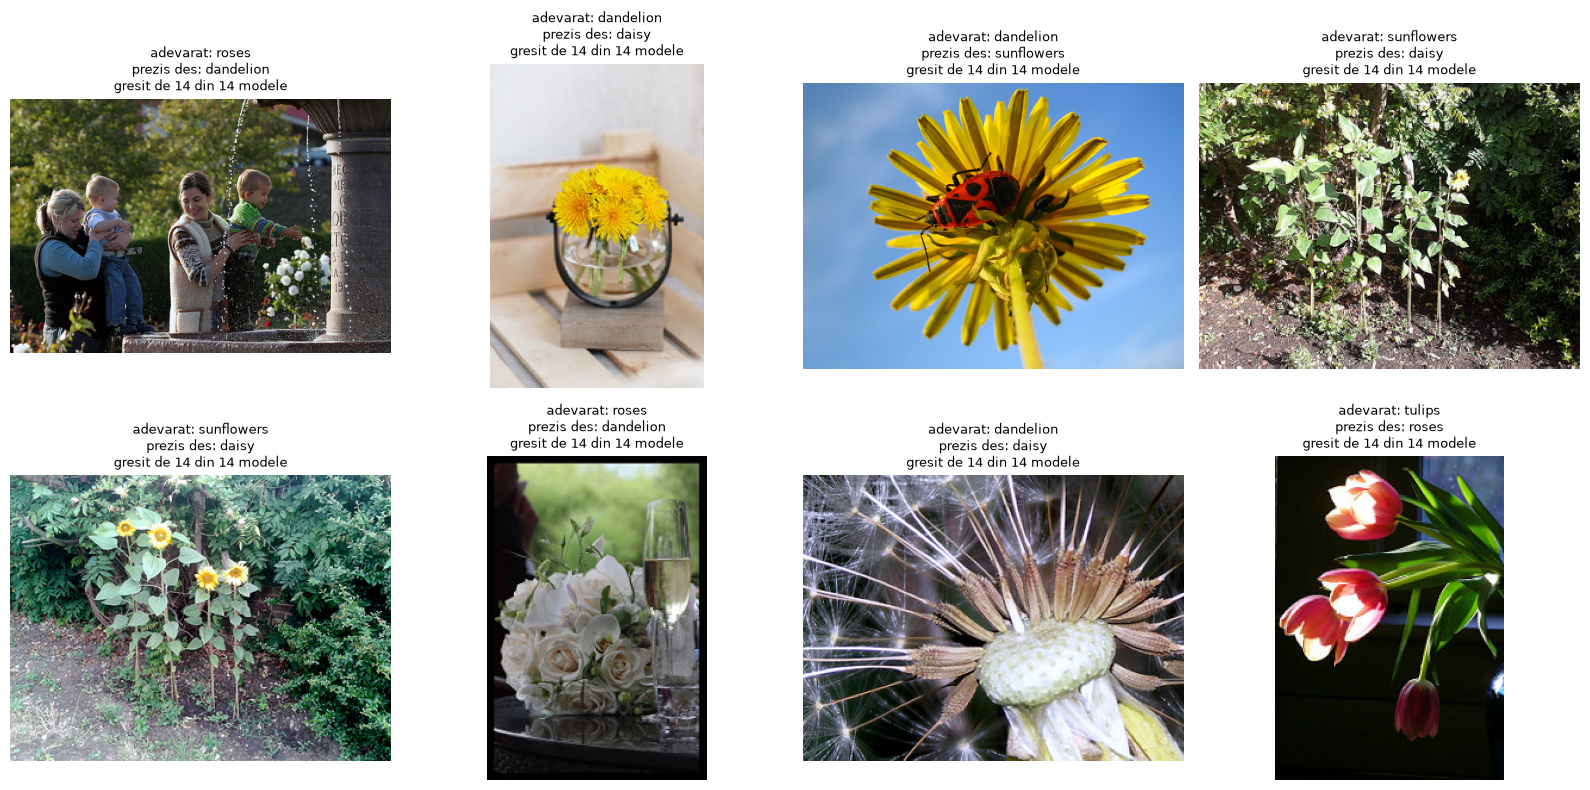

In [11]:
# ======================================================================
# LAB4 - PAS 11: POZELE CLASIFICATE GRESIT DE CELE MAI MULTE MODELE
# - pentru fiecare imagine numaram cate experimente au gresit-o (din predictiile out-of-fold)
# =========================================================================
toate_pred = {}
for cfg in EXPERIMENTE:
    cale = os.path.join(DIR_REZULTATE, cfg['nume'], 'pred_oof.npy')
    if os.path.exists(cale):
        toate_pred[cfg['nume']] = np.load(cale)
matrice_pred = np.array(list(toate_pred.values()))           # (experimente, imagini)
nr_gresite = (matrice_pred != etichete.numpy()).sum(axis=0)
cele_mai_gresite = np.argsort(-nr_gresite)[:8]

fig, axe = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axe.ravel(), cele_mai_gresite):
    pred_frecventa = np.bincount(matrice_pred[:, i], minlength=len(clase)).argmax()
    ax.imshow(Image.open(cai[i]).convert('RGB'))
    ax.set_title(f"adevarat: {clase[int(etichete[i])]}\nprezis des: {clase[pred_frecventa]}\n"
                 f"gresit de {nr_gresite[i]} din {len(toate_pred)} modele", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Interpretare: pozele clasificate gresit

- **241 de poze din 3670 sunt clasificate gresit de toate cele 14 experimente**, iar 720 sunt clasificate corect de toate. Pozele greu de clasificat nu sunt greseli intamplatoare ale unui singur model, ci poze cu adevarat dificile.
- Motive vazute in pozele afisate (la o alta rulare pot aparea alte poze, dar motivele raman aceleasi):
  - **Floarea e mica sau departe, iar altceva ocupa poza:** trandafirii din poza cu femei si copii la fantana, florile-soarelui mici dintr-o gradina plina de frunze. La 64x64 pixeli, floarea aproape dispare.
  - **Alta etapa a florii:** o papadie (dandelion) cu puful alb, fara petale galbene, prezisa ca margareta.
  - **Flori puse in vaza, cu alte obiecte:** papadii intr-o vaza de sticla, trandafiri albi langa un pahar cu sampanie, lalele intr-o vaza pe fundal intunecat.
  - **Unghi neobisnuit sau insecta pe floare:** o papadie vazuta de jos, pe cer albastru, cu o insecta rosie, prezisa ca floarea-soarelui.
  - **Culori asemanatoare:** trandafiri albi prezisi ca papadii, lalele rosii prezise ca trandafiri.
- Reteaua a invatat in principal culoarea si forma generala, nu "ce este o margareta". De aceea gresesc exact poze in care culoarea sau forma obisnuita lipsesc.
- La nivelul tuturor experimentelor, cele mai frecvente erori sunt tot trandafiri cu lalele si daisy cu dandelion. Unele poze din setul de date au si etichete discutabile.

CPU vs GPU 02_conv2_pool: {'experiment': '02_conv2_pool', 'timp_cpu_s': 9.2, 'timp_cuda_s': 3.1, 'de_cate_ori_mai_rapid_pe_GPU': 3.0}
CPU vs GPU 04_conv4_baza: {'experiment': '04_conv4_baza', 'timp_cpu_s': 12.0, 'timp_cuda_s': 3.6, 'de_cate_ori_mai_rapid_pe_GPU': 3.3}
CPU vs GPU 12_bn_dropout05: {'experiment': '12_bn_dropout05', 'timp_cpu_s': 17.7, 'timp_cuda_s': 4.3, 'de_cate_ori_mai_rapid_pe_GPU': 4.1}
Procesor: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD
Placa video: NVIDIA GeForce RTX 3050 6GB Laptop GPU
     experiment  timp_cpu_s  timp_cuda_s  de_cate_ori_mai_rapid_pe_GPU
  02_conv2_pool         9.2          3.1                           3.0
  04_conv4_baza        12.0          3.6                           3.3
12_bn_dropout05        17.7          4.3                           4.1


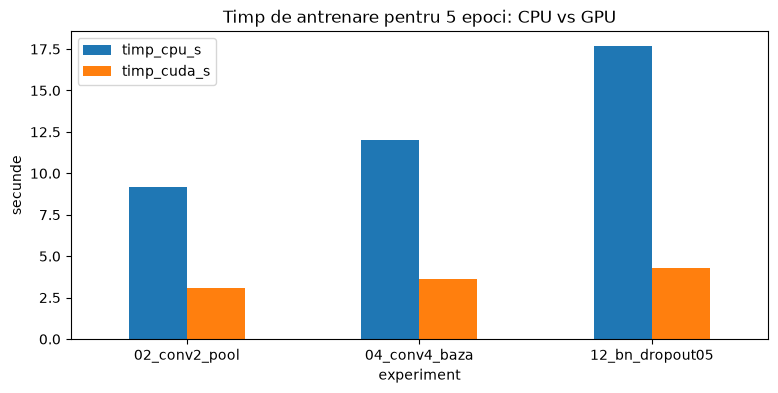

In [12]:
# ======================================================================
# LAB4 - PAS 12: TIMPUL DE ANTRENARE CPU vs GPU
# - 3 experimente, un singur fold, 5 epoci fixe, ca sa comparam doar viteza
# =========================================================================
if torch.cuda.is_available():
    comparatie = []
    idx_antr, idx_val = folduri[0]
    for nume in ['02_conv2_pool', '04_conv4_baza', '12_bn_dropout05']:
        cfg = next(c for c in EXPERIMENTE if c['nume'] == nume)
        rand = {'experiment': nume}
        for dev in [torch.device('cpu'), torch.device('cuda')]:
            _, _, _, durata = antreneaza(cfg, idx_antr, idx_val, dev, epoci_max=5)
            rand[f'timp_{dev.type}_s'] = round(durata, 1)
        rand['de_cate_ori_mai_rapid_pe_GPU'] = round(rand['timp_cpu_s'] / rand['timp_cuda_s'], 1)
        comparatie.append(rand)
        log(f"CPU vs GPU {nume}: {rand}")
    comparatie = pd.DataFrame(comparatie)
    comparatie.to_csv(os.path.join(DIR_REZULTATE, 'cpu_vs_gpu.csv'), index=False)
    print("Procesor:", platform.processor())
    print("Placa video:", torch.cuda.get_device_name(0))
    print(comparatie.to_string(index=False))
    comparatie.set_index('experiment')[['timp_cpu_s', 'timp_cuda_s']].plot(kind='bar', figsize=(9, 4), rot=0)
    plt.title('Timp de antrenare pentru 5 epoci: CPU vs GPU')
    plt.ylabel('secunde')
    plt.show()
else:
    print("Nu exista o placa video NVIDIA disponibila, deci comparatia CPU vs GPU nu se poate face pe acest calculator.")

### Interpretare: CPU vs GPU

Procesor: AMD Ryzen 7 8845HS. Placa video: NVIDIA GeForce RTX 3050 6GB Laptop. Timpii sunt pentru 5 epoci pe un singur fold.

| Experiment | CPU | GPU | De cate ori mai rapid |
|---|---|---|---|
| 02_conv2_pool | 9.2 s | 3.1 s | 3.0x |
| 04_conv4_baza | 12.0 s | 3.6 s | 3.3x |
| 12_bn_dropout05 | 17.7 s | 4.3 s | 4.1x |

- GPU-ul e de 3-4 ori mai rapid decat procesorul. Diferenta pare sa creasca la retelele mai mari, dar avem doar 3 experimente, deci nu e sigur.
- **De ce:** antrenarea inseamna multe inmultiri de matrice (convolutii, straturi liniare), iar GPU-ul le face in paralel pe mii de nuclee mici, pe cand procesorul are doar cateva nuclee puternice (cursul 5).
- Accelerarea e mai mica decat ar putea fi, pentru ca retelele sunt mici, pozele sunt mici (64x64), iar o parte din timp se pierde cu mutarea datelor intre procesor si placa video.

## Concluzie L4

- **Cel mai bun model:** experimentul 13 (4 straturi convolutionale cu pooling, dropout 0.25 si augmentare), cu macro-F1 de 0.736 pe 5 fold-uri, 360 mii de parametri si 1.45 MB pe disc.
- **Ce a ajutat:** convolutiile (de la 0.47 la 0.64-0.71), pooling-ul, augmentarea cu dropout (+0.04), batch norm cu dropout (+0.015); L1 a stabilizat rezultatele.
- **Ce nu a ajutat:** mai multi parametri (modelul cu 16,8 milioane e mai slab decat cel cu 360 mii), L2 mic, tanh, 3 straturi ascunse, GRU; o rata de invatare mare face antrenarea instabila.
- **Ce se confunda:** trandafirii cu lalelele si daisy cu dandelion; pozele grele au floarea mica, culori neobisnuite sau alte obiecte in poza. La 64x64 pixeli multe detalii se pierd.
- **GPU:** de 3-4 ori mai rapid decat procesorul. Toate cele 14 experimente, cu 5 fold-uri, au durat aprox. 18 minute pe GPU.